In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

In [3]:
df = pd.read_csv('malicious_phish.csv')

In [5]:
df

,url,type
0,br-icloud.com.br,phishing
1,mp3raid.com/music/krizz_kaliko.html,benign
2,bopsecrets.org/rexroth/cr/1.htm,benign
3,http://www.garage-pirenne.be/index.php?option=...,defacement
4,http://adventure-nicaragua.net/index.php?optio...,defacement
...,...,...
651186,xbox360.ign.com/objects/850/850402.html,phishing
651187,games.teamxbox.com/xbox-360/1860/Dead-Space/,phishing
651188,www.gamespot.com/xbox360/action/deadspace/,phishing
651189,en.wikipedia.org/wiki/Dead_Space_(video_game),phishing


In [7]:
df['type'].value_counts()

type
benign        428103
defacement     96457
phishing       94111
malware        32520
Name: count, dtype: int64

In [9]:
df = df[df['type'] != 'benign']

In [11]:
df['type'].value_counts()

type
defacement    96457
phishing      94111
malware       32520
Name: count, dtype: int64

### 추가할 열 
- domain_token_count : 도메인 토큰 수
- executable : URL이 실행 파일과 관련 있는지 여부 (0, 1)
- NumberofDotsinURL : URL에 .(dot )의 개수
- Arguments_LongestWordLength : 문자 쿼리에서 가장 긴 단어 길이
- NumberRate_Domain : 도메인의 숫자 비율
- NumberRate_FileName : 파일 이름에서 숫자 비율
- NumberRate_AfterPath : Path 경로 이후 숫자 비율
- Entropy_Domain : 도메인 엔트로피(복잡도)
    - 랜덤하게 생성된 도메인(`a8d9k3l.com`)은 엔트로피가 높음
    - 의미 있는 단어로 구성된 도메인(`example.com`)은 엔트로피가 낮음
    - 엔트로피가 높을 수 있음

### y

In [17]:
import tldextract
import urllib.parse
import math
import re

In [25]:
def extract_features(url):
    parsed = urllib.parse.urlparse(url)
    path = parsed.path
    query = parsed.query
    domain_info = tldextract.extract(url)
    domain = domain_info.domain + '.' + domain_info.suffix
    filename = path.split('/')[-1] if '/' in path else ''

    # domain_token_count
    domain_token_count = len(domain.split('.'))

    # executable (실행파일 여부)
    executable = int(any(ext in filename.lower() for ext in ['.exe', '.bat', '.cmd', '.scr', '.msi']))

    # NumberofDotsinURL
    number_of_dots = url.count('.')

    # Arguments_LongestWordLength
    if query:
        query_words = re.split(r'[=&]', query)
        longest_word_length = max((len(w) for w in query_words if w.isalpha()), default=-1)
    else:
        longest_word_length = -1

    # NumberRate_Domain
    number_rate_domain = sum(c.isdigit() for c in domain) / len(domain) if domain else 0

    # NumberRate_FileName
    if filename:
        number_rate_filename = sum(c.isdigit() for c in filename) / len(filename)
    else:
        number_rate_filename = -1

    # NumberRate_AfterPath
    after_path = parsed.params + parsed.query + parsed.fragment
    if after_path:
        number_rate_afterpath = sum(c.isdigit() for c in after_path) / len(after_path)
    else:
        number_rate_afterpath = -1

    # Entropy_Domain
    def calc_entropy(s):
        prob = [float(s.count(c)) / len(s) for c in set(s)]
        return -sum(p * math.log2(p) for p in prob)

    entropy_domain = calc_entropy(domain) if domain else 0

    return pd.Series([
        domain_token_count,
        executable,
        number_of_dots,
        longest_word_length,
        number_rate_domain,
        number_rate_filename,
        number_rate_afterpath,
        entropy_domain
    ])

In [27]:
feature_columns = [
    'domain_token_count',
    'executable',
    'NumberofDotsinURL',
    'Arguments_LongestWordLength',
    'NumberRate_Domain',
    'NumberRate_FileName',
    'NumberRate_AfterPath',
    'Entropy_Domain'
]

df[feature_columns] = df['url'].apply(extract_features)


In [29]:
df.columns

Index(['url', 'type', 'domain_token_count', 'executable', 'NumberofDotsinURL',
       'Arguments_LongestWordLength', 'NumberRate_Domain',
       'NumberRate_FileName', 'NumberRate_AfterPath', 'Entropy_Domain'],
      dtype='object')

In [31]:
df

,url,type,domain_token_count,executable,NumberofDotsinURL,Arguments_LongestWordLength,NumberRate_Domain,NumberRate_FileName,NumberRate_AfterPath,Entropy_Domain
0,br-icloud.com.br,phishing,3.0,0.0,2.0,-1.0,0.0,-1.000000,-1.000000,3.375000
3,http://www.garage-pirenne.be/index.php?option=...,defacement,2.0,0.0,3.0,7.0,0.0,0.000000,0.142857,3.146286
4,http://adventure-nicaragua.net/index.php?optio...,defacement,2.0,0.0,2.0,9.0,0.0,0.000000,0.113402,3.501398
8,http://www.pashminaonline.com/pure-pashminas,defacement,2.0,0.0,2.0,-1.0,0.0,0.000000,-1.000000,3.461320
11,http://www.ikenmijnkunst.nl/index.php/expositi...,defacement,2.0,0.0,3.0,-1.0,0.0,0.266667,-1.000000,3.250000
...,...,...,...,...,...,...,...,...,...,...
651186,xbox360.ign.com/objects/850/850402.html,phishing,2.0,0.0,3.0,-1.0,0.0,0.545455,-1.000000,2.807355
651187,games.teamxbox.com/xbox-360/1860/Dead-Space/,phishing,2.0,0.0,2.0,-1.0,0.0,-1.000000,-1.000000,3.084963
651188,www.gamespot.com/xbox360/action/deadspace/,phishing,2.0,0.0,2.0,-1.0,0.0,-1.000000,-1.000000,3.251629
651189,en.wikipedia.org/wiki/Dead_Space_(video_game),phishing,2.0,0.0,2.0,-1.0,0.0,0.000000,-1.000000,3.334679


In [33]:
new_order = ['url', 'executable', 'Entropy_Domain', 'domain_token_count', 
             'NumberofDotsinURL', 'Arguments_LongestWordLength', 
             'NumberRate_Domain', 'NumberRate_FileName', 'NumberRate_AfterPath', 'type']

df = df[new_order]

In [35]:
df

,url,executable,Entropy_Domain,domain_token_count,NumberofDotsinURL,Arguments_LongestWordLength,NumberRate_Domain,NumberRate_FileName,NumberRate_AfterPath,type
0,br-icloud.com.br,0.0,3.375000,3.0,2.0,-1.0,0.0,-1.000000,-1.000000,phishing
3,http://www.garage-pirenne.be/index.php?option=...,0.0,3.146286,2.0,3.0,7.0,0.0,0.000000,0.142857,defacement
4,http://adventure-nicaragua.net/index.php?optio...,0.0,3.501398,2.0,2.0,9.0,0.0,0.000000,0.113402,defacement
8,http://www.pashminaonline.com/pure-pashminas,0.0,3.461320,2.0,2.0,-1.0,0.0,0.000000,-1.000000,defacement
11,http://www.ikenmijnkunst.nl/index.php/expositi...,0.0,3.250000,2.0,3.0,-1.0,0.0,0.266667,-1.000000,defacement
...,...,...,...,...,...,...,...,...,...,...
651186,xbox360.ign.com/objects/850/850402.html,0.0,2.807355,2.0,3.0,-1.0,0.0,0.545455,-1.000000,phishing
651187,games.teamxbox.com/xbox-360/1860/Dead-Space/,0.0,3.084963,2.0,2.0,-1.0,0.0,-1.000000,-1.000000,phishing
651188,www.gamespot.com/xbox360/action/deadspace/,0.0,3.251629,2.0,2.0,-1.0,0.0,-1.000000,-1.000000,phishing
651189,en.wikipedia.org/wiki/Dead_Space_(video_game),0.0,3.334679,2.0,2.0,-1.0,0.0,0.000000,-1.000000,phishing


In [37]:
df = df.rename(columns={'type':'class'})

In [39]:
df

,url,executable,Entropy_Domain,domain_token_count,NumberofDotsinURL,Arguments_LongestWordLength,NumberRate_Domain,NumberRate_FileName,NumberRate_AfterPath,class
0,br-icloud.com.br,0.0,3.375000,3.0,2.0,-1.0,0.0,-1.000000,-1.000000,phishing
3,http://www.garage-pirenne.be/index.php?option=...,0.0,3.146286,2.0,3.0,7.0,0.0,0.000000,0.142857,defacement
4,http://adventure-nicaragua.net/index.php?optio...,0.0,3.501398,2.0,2.0,9.0,0.0,0.000000,0.113402,defacement
8,http://www.pashminaonline.com/pure-pashminas,0.0,3.461320,2.0,2.0,-1.0,0.0,0.000000,-1.000000,defacement
11,http://www.ikenmijnkunst.nl/index.php/expositi...,0.0,3.250000,2.0,3.0,-1.0,0.0,0.266667,-1.000000,defacement
...,...,...,...,...,...,...,...,...,...,...
651186,xbox360.ign.com/objects/850/850402.html,0.0,2.807355,2.0,3.0,-1.0,0.0,0.545455,-1.000000,phishing
651187,games.teamxbox.com/xbox-360/1860/Dead-Space/,0.0,3.084963,2.0,2.0,-1.0,0.0,-1.000000,-1.000000,phishing
651188,www.gamespot.com/xbox360/action/deadspace/,0.0,3.251629,2.0,2.0,-1.0,0.0,-1.000000,-1.000000,phishing
651189,en.wikipedia.org/wiki/Dead_Space_(video_game),0.0,3.334679,2.0,2.0,-1.0,0.0,0.000000,-1.000000,phishing


In [41]:
df['class'].value_counts()

class
defacement    96457
phishing      94111
malware       32520
Name: count, dtype: int64

In [43]:
(df==-1).sum()

url                                 0
executable                          0
Entropy_Domain                      0
domain_token_count                  0
NumberofDotsinURL                   0
Arguments_LongestWordLength    158262
NumberRate_Domain                   0
NumberRate_FileName             55640
NumberRate_AfterPath           155365
class                               0
dtype: int64

In [45]:
# -1이 있는 행 삭제
df_cleaned = df[~(df == -1).any(axis=1)]

In [47]:
df_cleaned['class'].value_counts()

class
defacement    53841
phishing       5516
malware        3505
Name: count, dtype: int64

In [51]:
df_cleaned = df_cleaned[df_cleaned['class'] != 'defacement']

In [53]:
df_cleaned['class'].value_counts()

class
phishing    5516
malware     3505
Name: count, dtype: int64

In [59]:
df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9021 entries, 38 to 651181
Data columns (total 10 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   url                          9021 non-null   object 
 1   executable                   9021 non-null   float64
 2   Entropy_Domain               9021 non-null   float64
 3   domain_token_count           9021 non-null   float64
 4   NumberofDotsinURL            9021 non-null   float64
 5   Arguments_LongestWordLength  9021 non-null   float64
 6   NumberRate_Domain            9021 non-null   float64
 7   NumberRate_FileName          9021 non-null   float64
 8   NumberRate_AfterPath         9021 non-null   float64
 9   class                        9021 non-null   object 
dtypes: float64(8), object(2)
memory usage: 775.2+ KB


In [61]:
df_cleaned = df_cleaned.drop(columns=['url'])

In [65]:
df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9021 entries, 38 to 651181
Data columns (total 9 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   executable                   9021 non-null   float64
 1   Entropy_Domain               9021 non-null   float64
 2   domain_token_count           9021 non-null   float64
 3   NumberofDotsinURL            9021 non-null   float64
 4   Arguments_LongestWordLength  9021 non-null   float64
 5   NumberRate_Domain            9021 non-null   float64
 6   NumberRate_FileName          9021 non-null   float64
 7   NumberRate_AfterPath         9021 non-null   float64
 8   class                        9021 non-null   object 
dtypes: float64(8), object(1)
memory usage: 704.8+ KB


In [67]:
df_cleaned.columns

Index(['executable', 'Entropy_Domain', 'domain_token_count',
       'NumberofDotsinURL', 'Arguments_LongestWordLength', 'NumberRate_Domain',
       'NumberRate_FileName', 'NumberRate_AfterPath', 'class'],
      dtype='object')

In [69]:
new_col = ['domain_token_count','executable', 'NumberofDotsinURL', 'Arguments_LongestWordLength',
           'NumberRate_Domain', 'NumberRate_FileName', 'NumberRate_AfterPath', 
           'Entropy_Domain', 'class']

In [71]:
df_cleaned = df_cleaned[new_col]

In [75]:
df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9021 entries, 38 to 651181
Data columns (total 9 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   domain_token_count           9021 non-null   float64
 1   executable                   9021 non-null   float64
 2   NumberofDotsinURL            9021 non-null   float64
 3   Arguments_LongestWordLength  9021 non-null   float64
 4   NumberRate_Domain            9021 non-null   float64
 5   NumberRate_FileName          9021 non-null   float64
 6   NumberRate_AfterPath         9021 non-null   float64
 7   Entropy_Domain               9021 non-null   float64
 8   class                        9021 non-null   object 
dtypes: float64(8), object(1)
memory usage: 704.8+ KB


In [77]:
df_cleaned.to_csv("kaggle_plus.csv", index=False, encoding='utf-8')

In [79]:
df1 = pd.read_csv("kaggle_plus.csv")

In [81]:
df2 = pd.read_csv("for_modeling_2.csv")

In [83]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9021 entries, 0 to 9020
Data columns (total 9 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   domain_token_count           9021 non-null   float64
 1   executable                   9021 non-null   float64
 2   NumberofDotsinURL            9021 non-null   float64
 3   Arguments_LongestWordLength  9021 non-null   float64
 4   NumberRate_Domain            9021 non-null   float64
 5   NumberRate_FileName          9021 non-null   float64
 6   NumberRate_AfterPath         9021 non-null   float64
 7   Entropy_Domain               9021 non-null   float64
 8   class                        9021 non-null   object 
dtypes: float64(8), object(1)
memory usage: 634.4+ KB


In [85]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14510 entries, 0 to 14509
Data columns (total 10 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Unnamed: 0                   14510 non-null  int64  
 1   domain_token_count           14510 non-null  int64  
 2   executable                   14510 non-null  int64  
 3   NumberofDotsinURL            14510 non-null  int64  
 4   Arguments_LongestWordLength  14510 non-null  int64  
 5   NumberRate_Domain            14510 non-null  float64
 6   NumberRate_FileName          14510 non-null  float64
 7   NumberRate_AfterPath         14510 non-null  float64
 8   Entropy_Domain               14510 non-null  float64
 9   class                        14510 non-null  object 
dtypes: float64(4), int64(5), object(1)
memory usage: 1.1+ MB


In [87]:
df2 = df2.drop(columns=['Unnamed: 0'])

In [89]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14510 entries, 0 to 14509
Data columns (total 9 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   domain_token_count           14510 non-null  int64  
 1   executable                   14510 non-null  int64  
 2   NumberofDotsinURL            14510 non-null  int64  
 3   Arguments_LongestWordLength  14510 non-null  int64  
 4   NumberRate_Domain            14510 non-null  float64
 5   NumberRate_FileName          14510 non-null  float64
 6   NumberRate_AfterPath         14510 non-null  float64
 7   Entropy_Domain               14510 non-null  float64
 8   class                        14510 non-null  object 
dtypes: float64(4), int64(4), object(1)
memory usage: 1020.4+ KB


In [91]:
df = pd.concat([df1, df2], axis=0, ignore_index=True)

In [93]:
df['class'].value_counts()

class
malware       6529
phishing      6331
Defacement    5757
spam          4914
Name: count, dtype: int64

class 분포 확인


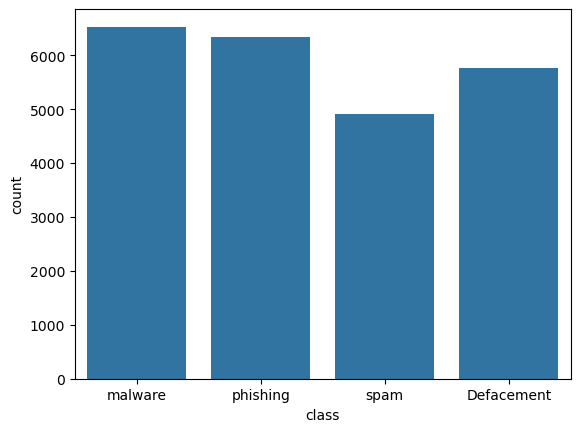

In [95]:
# 클래스 분포 확인
sns.countplot(x = df['class'], data = df)
print("class 분포 확인")

In [97]:
# 한글 폰트 설정
from matplotlib import font_manager, rc

font_path = "C:/Windows/Fonts/malgun.ttf"
font = font_manager.FontProperties(fname=font_path).get_name()
rc('font', family=font)
plt.rcParams['axes.unicode_minus'] = False  # 마이너스 깨짐 방지

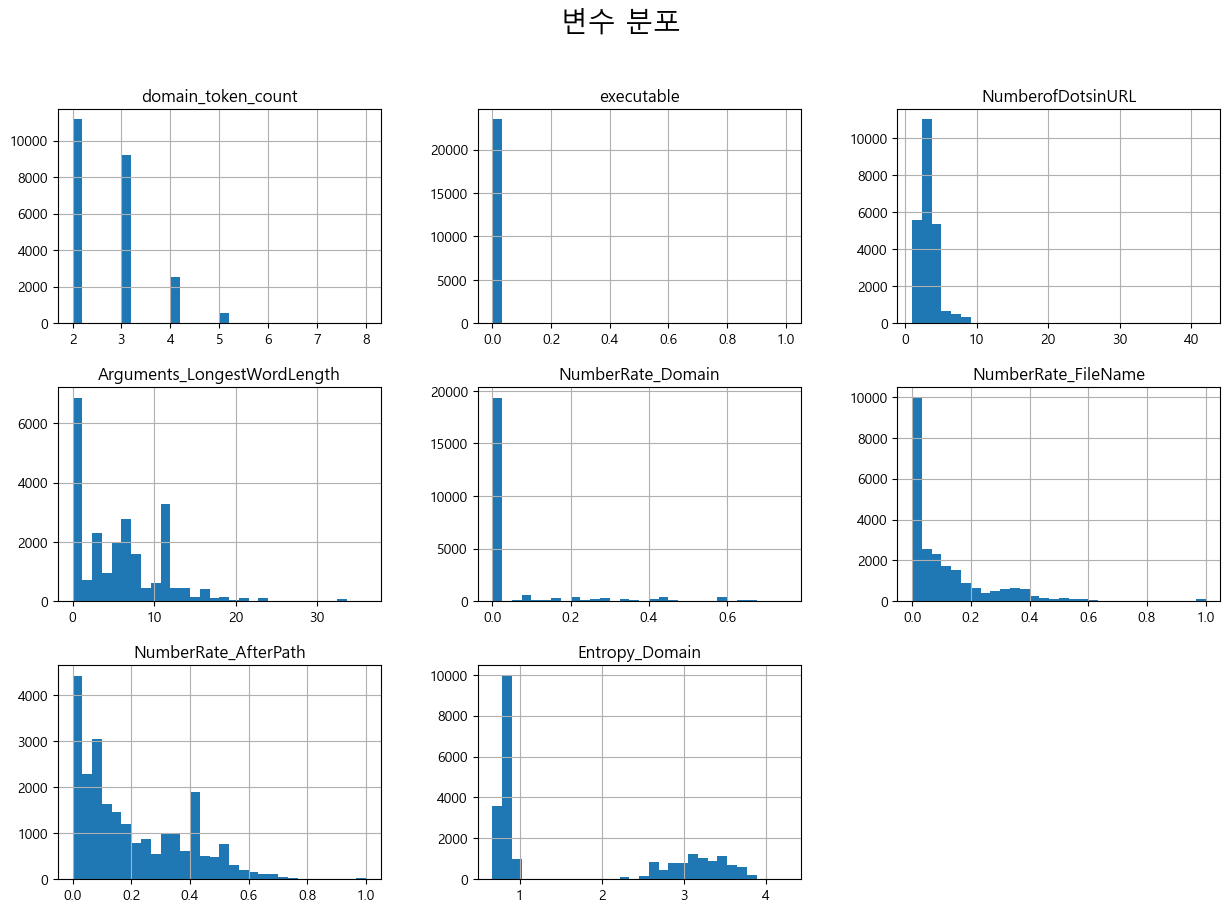

In [99]:
# 주요 feature 분포 확인
df.hist(bins=30, figsize=(15, 10))
plt.suptitle("변수 분포", fontsize=20)
plt.show()

In [101]:
# executable 컬럼의 값 확인
df['executable'].unique()

array([0., 1.])

In [103]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, RocCurveDisplay

In [105]:
df.columns

Index(['domain_token_count', 'executable', 'NumberofDotsinURL',
       'Arguments_LongestWordLength', 'NumberRate_Domain',
       'NumberRate_FileName', 'NumberRate_AfterPath', 'Entropy_Domain',
       'class'],
      dtype='object')

In [107]:
selected_features = [
    'domain_token_count', 'executable', 'NumberofDotsinURL',
       'Arguments_LongestWordLength', 'NumberRate_Domain',
       'NumberRate_FileName', 'NumberRate_AfterPath', 'Entropy_Domain'
]

In [109]:
X = df[selected_features]
y = df['class']

In [111]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [113]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [121]:
model = DecisionTreeClassifier(
    random_state=42
)
model.fit(X_train_scaled, y_train)

DecisionTreeClassifier(random_state=42)

In [123]:
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

In [125]:
print("📌 [Confusion Matrix]")
print(confusion_matrix(y_test, y_pred))
print("\n📌 [Classification Report]")
print(classification_report(y_test, y_pred))

📌 [Confusion Matrix]
[[1138    2    7    4]
 [   1 1294   18    0]
 [   9   37 1225   11]
 [  11    2    4  944]]

📌 [Classification Report]
              precision    recall  f1-score   support

  Defacement       0.98      0.99      0.99      1151
     malware       0.97      0.99      0.98      1313
    phishing       0.98      0.96      0.97      1282
        spam       0.98      0.98      0.98       961

    accuracy                           0.98      4707
   macro avg       0.98      0.98      0.98      4707
weighted avg       0.98      0.98      0.98      4707



In [128]:
model = DecisionTreeClassifier(
    max_depth=20,    
    random_state=42
)
model.fit(X_train_scaled, y_train)

DecisionTreeClassifier(max_depth=20, random_state=42)

In [130]:
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

In [132]:
print("📌 [Confusion Matrix]")
print(confusion_matrix(y_test, y_pred))
print("\n📌 [Classification Report]")
print(classification_report(y_test, y_pred))

📌 [Confusion Matrix]
[[1138    2    7    4]
 [   1 1292   20    0]
 [  10   33 1229   10]
 [  12    2    4  943]]

📌 [Classification Report]
              precision    recall  f1-score   support

  Defacement       0.98      0.99      0.98      1151
     malware       0.97      0.98      0.98      1313
    phishing       0.98      0.96      0.97      1282
        spam       0.99      0.98      0.98       961

    accuracy                           0.98      4707
   macro avg       0.98      0.98      0.98      4707
weighted avg       0.98      0.98      0.98      4707



In [135]:
from sklearn.ensemble import RandomForestClassifier

rfm = RandomForestClassifier(random_state=42)
rfm.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [136]:
y_pred = rfm.predict(X_test)

In [139]:
report = classification_report(y_test, y_pred, digits=2)
matrix = confusion_matrix(y_test, y_pred)

In [145]:
print("📌 [Confusion Matrix]")
print(matrix)
print("\n📌 [Classification Report]")
print(report)

📌 [Confusion Matrix]
[[1144    1    2    4]
 [   1 1304    8    0]
 [   7   17 1250    8]
 [  11    0    7  943]]

📌 [Classification Report]
              precision    recall  f1-score   support

  Defacement       0.98      0.99      0.99      1151
     malware       0.99      0.99      0.99      1313
    phishing       0.99      0.98      0.98      1282
        spam       0.99      0.98      0.98       961

    accuracy                           0.99      4707
   macro avg       0.99      0.99      0.99      4707
weighted avg       0.99      0.99      0.99      4707



In [147]:
from sklearn.ensemble import RandomForestClassifier

rfm = RandomForestClassifier(random_state=42,
                            max_depth=20)
rfm.fit(X_train, y_train)

RandomForestClassifier(max_depth=20, random_state=42)

In [148]:
y_pred = rfm.predict(X_test)

In [149]:
report = classification_report(y_test, y_pred, digits=2)
matrix = confusion_matrix(y_test, y_pred)

In [150]:
print("📌 [Confusion Matrix]")
print(matrix)
print("\n📌 [Classification Report]")
print(report)

📌 [Confusion Matrix]
[[1144    2    2    3]
 [   1 1304    8    0]
 [   8   17 1251    6]
 [  11    0    6  944]]

📌 [Classification Report]
              precision    recall  f1-score   support

  Defacement       0.98      0.99      0.99      1151
     malware       0.99      0.99      0.99      1313
    phishing       0.99      0.98      0.98      1282
        spam       0.99      0.98      0.99       961

    accuracy                           0.99      4707
   macro avg       0.99      0.99      0.99      4707
weighted avg       0.99      0.99      0.99      4707



In [155]:
from sklearn.ensemble import RandomForestClassifier

rfm = RandomForestClassifier(random_state=42,
                            max_depth=15)
rfm.fit(X_train, y_train)

RandomForestClassifier(max_depth=15, random_state=42)

In [156]:
y_pred = rfm.predict(X_test)

In [157]:
report = classification_report(y_test, y_pred, digits=2)
matrix = confusion_matrix(y_test, y_pred)

In [158]:
print("📌 [Confusion Matrix]")
print(matrix)
print("\n📌 [Classification Report]")
print(report)

📌 [Confusion Matrix]
[[1145    1    2    3]
 [   2 1296   12    3]
 [  14   16 1242   10]
 [  16    2    3  940]]

📌 [Classification Report]
              precision    recall  f1-score   support

  Defacement       0.97      0.99      0.98      1151
     malware       0.99      0.99      0.99      1313
    phishing       0.99      0.97      0.98      1282
        spam       0.98      0.98      0.98       961

    accuracy                           0.98      4707
   macro avg       0.98      0.98      0.98      4707
weighted avg       0.98      0.98      0.98      4707

